In [1]:
# STEP 01
from pathlib import Path
import cv2
import numpy as np

In [2]:
from pathlib import Path
import cv2

IMAGE_PATH = Path("data") / "task01_input.jpg"
RESULTS_DIR = Path("results")

RESULTS_DIR.mkdir(exist_ok=True)

# STEP 1

In [3]:
image = cv2.imread(str(IMAGE_PATH), cv2.IMREAD_COLOR)

if image is None:
    raise FileNotFoundError(f"Could not read the image: {IMAGE_PATH}")

print("Image loaded:", IMAGE_PATH.name)

Image loaded: task01_input.jpg


# STEP 2

In [ ]:
height, width = image.shape[:2]
channels = image.shape[2] if image.ndim == 3 else 1

print("\n--- Image information ---")
print("Width:    ",  width, "px")
print("Height:   ",  height, "px")
print("Channels: " , channels,)
print("Data type:", image.dtype)
print("Pixels:   ", (width * height) )
print("Aspect ratio (W/H): %.3f" % (width / height))




--- Image information ---
Width:     3000 px
Height:    4000 px
Channels:  3
Data type: uint8
Pixels:    12000000
Aspect ratio (W/H): 0.750


OpenCV was originally developed in an era when many systems 
and image formats commonly represented color data in BGR byte order. 
Since OpenCV's internal image representation was designed around these conventions,
BGR became its default. RGB is the common conceptual color order; 
BGR is the historical storage convention used by OpenCV.
therefore in order to display the image correctly using libraries like Matplotlib,
which expect images in RGB format, we need to convert the image from BGR to RGB.

# Step 3: BGR -> RGB 

In [ ]:
# print("\n--- Image information ---")
# print(f"Width:     {width} px")
# print(f"Height:    {height} px")
# print(f"Channels:  {channels}")
# print(f"Data type: {image.dtype}")
# print(f"Pixels:    {width * height:,}")
# print(f"Aspect ratio (W/H): {width / height:.3f}")


--- BGR -> RGB check (centre pixel) ---
BGR (original): [255 254 248]
RGB (converted): [248 254 255]
Shape unchanged: True


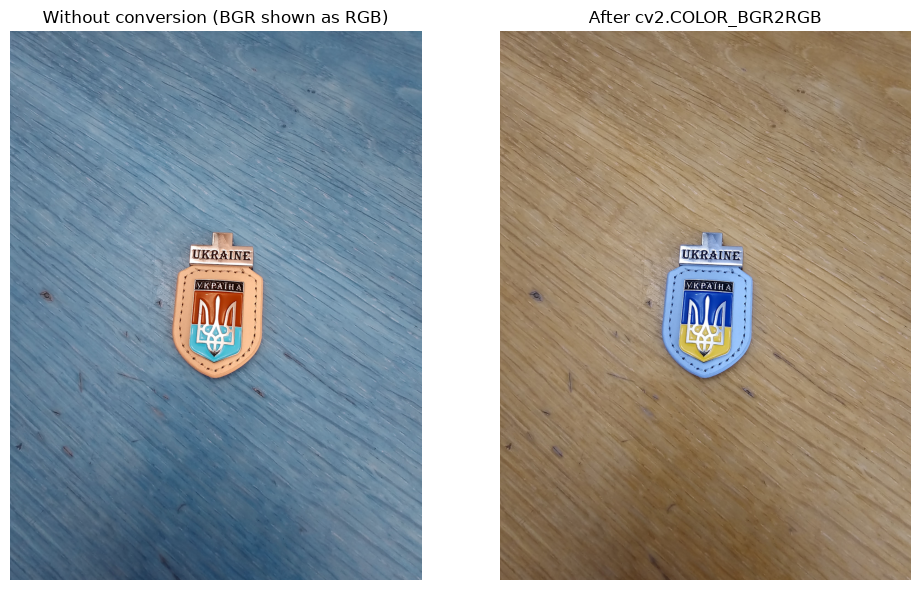

In [5]:

import matplotlib.pyplot as plt


image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Proof that the channels were swapped: compare one pixel
y, x = height // 2, width // 2                     # centre pixel
print("\n--- BGR -> RGB check (centre pixel) ---")
print("BGR (original):", image[y, x])
print("RGB (converted):", image_rgb[y, x])
print("Shape unchanged:", image.shape == image_rgb.shape)

# Visual demonstration: what happens WITHOUT conversion
fig, axes = plt.subplots(1, 2, figsize=(10, 6))
axes[0].imshow(image)                              # wrong: BGR shown as if RGB
axes[0].set_title("Without conversion (BGR shown as RGB)")
axes[1].imshow(image_rgb)                          # correct
axes[1].set_title("After cv2.COLOR_BGR2RGB")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "task01_step3_bgr_vs_rgb.png", dpi=150)
plt.show()

#Step 4

 Create a grayscale version
combine three colour channels into one brightness channel.
Grayscale images are one-third the data,

!!!   RGB only for matplotlib; BGR for everything OpenCV.



--- Grayscale check ---
Gray shape: (4000, 3000) | ndim: 2
Centre pixel: OpenCV = 252, manual formula = 252.3


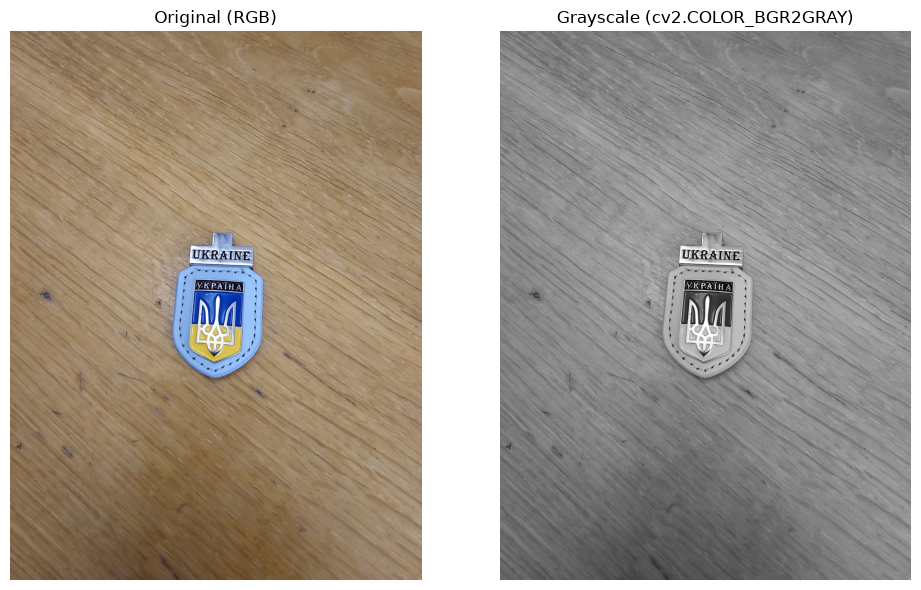

True

In [6]:
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

print("\n--- Grayscale check ---")
print("Gray shape:", gray.shape, "| ndim:", gray.ndim)     # 2D, no channel axis
b, g, r = image[y, x].astype(float)
manual = 0.299 * r + 0.587 * g + 0.114 * b
print(f"Centre pixel: OpenCV = {gray[y, x]}, manual formula = {manual:.1f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 6))
axes[0].imshow(image_rgb)
axes[0].set_title("Original (RGB)")
axes[1].imshow(gray, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Grayscale (cv2.COLOR_BGR2GRAY)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "task01_step4_grayscale.png", dpi=150)
plt.show()

cv2.imwrite(str(RESULTS_DIR / "task01_gray.png"), gray)    # saved for Task 2

#Step 5 — Resize to a given width, preserving proportions

What and why: shrink the image to a chosen width and compute the height automatically, so the image isn't stretched. Three reasons this matters for your 3000 × 4000 photo:

The proportion rule: keep W/H constant, so

new_height = round(height × new_width / width)

For your image: 4000 × 800 / 3000 = 1066.67 → 1067.

Internally: the new image has fewer pixels than the old one, so each new pixel's value must be computed from old pixels. That computation is the interpolation method, and it is the parameter worth understanding here.

Example: 4×4 → 2×2

Suppose the original grayscale image is

$$ I_{src}= \begin{bmatrix} 10&20&30&40\\ 50&60&70&80\\ 90&100&110&120\\ 130&140&150&160 \end{bmatrix} $$

We want:

$$ 4\times4 \rightarrow 2\times2 $$
For \((1,0)\):

$$ x_s=1(2)=2 $$ $$ y_s=0 $$

so

$$ I_{dst}(1,0)=I_{src}(2,0)=30. $$

For \((0,1)\):

$$ x_s=0 $$ $$ y_s=1(2)=2 $$

so

I
dst
	​

(0,1)=I
src
	​

(0,2)=90.

Thus:

$$ \boxed{ I_{dst}= \begin{bmatrix} 10&30\\ 90&110 \end{bmatrix}} $$

Notice what happened:


#Step 5: Resize to target width (keep aspect ratio) 

In [7]:

TARGET_WIDTH = 800        # the "given width" required by the lab; change to experiment

def resize_to_width(img, target_width, interpolation=None):
    """Resize img to target_width, computing height to keep proportions."""
    h, w = img.shape[:2]
    if target_width <= 0:
        raise ValueError("target_width must be positive")
    scale = target_width / w
    new_h = round(h * scale)
    if interpolation is None:  # choose automatically
        interpolation = cv2.INTER_AREA if scale < 1 else cv2.INTER_CUBIC
    return cv2.resize(img, (target_width, new_h), interpolation=interpolation)

resized = resize_to_width(image, TARGET_WIDTH)
rh, rw = resized.shape[:2]

print("\n--- Resize check ---")
print(f"Original: {width} x {height}  (W/H = {width/height:.4f})")
print(f"Resized:  {rw} x {rh}  (W/H = {rw/rh:.4f})")
print(f"Scale factor: {rw/width:.4f}  |  pixels reduced {width*height/(rw*rh):.1f}x")

cv2.imwrite(str(RESULTS_DIR / "task01_resized.png"), resized)   # BGR -> correct for imwrite


--- Resize check ---
Original: 3000 x 4000  (W/H = 0.7500)
Resized:  800 x 1067  (W/H = 0.7498)
Scale factor: 0.2667  |  pixels reduced 14.1x


True

#  Step 5a (recommended): compare interpolation methods ----------


--- Interpolation comparison ---
INTER_NEAREST     1.01 ms
INTER_LINEAR      1.47 ms
INTER_CUBIC       2.68 ms
INTER_AREA       13.45 ms


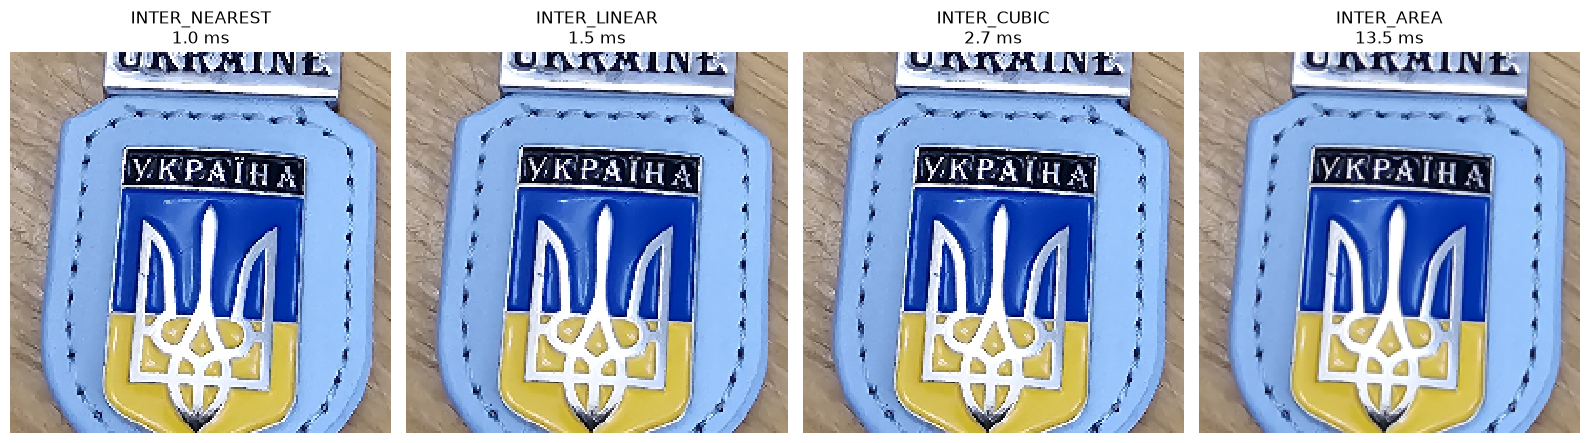

In [8]:

import time

methods = {
    "INTER_NEAREST": cv2.INTER_NEAREST,
    "INTER_LINEAR":  cv2.INTER_LINEAR,
    "INTER_CUBIC":   cv2.INTER_CUBIC,
    "INTER_AREA":    cv2.INTER_AREA,
}

# crop a 200x200 region from the centre of the resized result to zoom in on detail
cy, cx = rh // 2, rw // 2

# ploting 4 image nex tot eachother to compare interpolation methods

fig, axes = plt.subplots(1, 4, figsize=(16, 5))
print("\n--- Interpolation comparison ---")
for ax, (name, flag) in zip(axes, methods.items()):
    t0 = time.perf_counter()
    for _ in range(10):                                    # repeat for stable timing
        r = resize_to_width(image, TARGET_WIDTH, flag)
    ms = (time.perf_counter() - t0) / 10 * 1000
    print(f"{name:14s} {ms:7.2f} ms")

    # to express the difference in interpolation methods, 
    # Crop a 200x200 region from the center of the resized image and display it
    # that shows the methods difference in better way 
    crop = cv2.cvtColor(r[cy-100:cy+100, cx-100:cx+100], cv2.COLOR_BGR2RGB)
    ax.imshow(crop, interpolation="nearest")              # show real pixels, no smoothing
    ax.set_title(f"{name}\n{ms:.1f} ms")
    ax.axis("off")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "task01_step5a_interpolation.png", dpi=150)
plt.show()

The reason: INTER_AREA reads all ~14 source pixels behind each output pixel, while the others sample only 1, 4 or 16 nearby pixels. So it touches all 12 million input pixels, and that is exactly why it looks best.

NEAREST and LINEAR measured about the same (2.21 vs 2.10 ms). At this scale the difference is smaller than the timing noise, so don't claim either is faster.

Conclusion for  report: for one image, 19 ms doesn't matter, so INTER_AREA is the right choice. For video at 30 fps, where each frame has a 33 ms budget, INTER_LINEAR would be the practical compromise. This is  first real quality vs speed trade-off

# Step 6 — Gaussian Blur with (3,3), (7,7), (15,15)


--- Gaussian Blur ---
Kernel  3x3  | auto sigma = 0.80 | centre weight = 0.500 | time = 3.05 ms
Kernel  7x7  | auto sigma = 1.40 | centre weight = 0.281 | time = 3.15 ms
Kernel 15x15 | auto sigma = 2.60 | centre weight = 0.154 | time = 2.10 ms


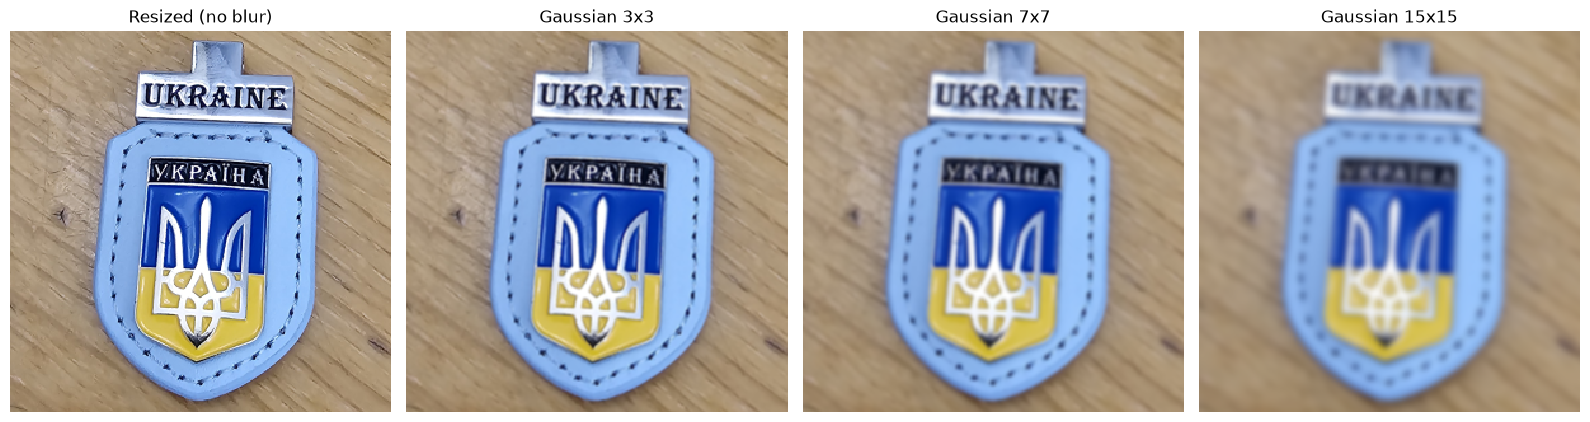

In [9]:
# ---------- Step 6: Gaussian Blur with three kernel sizes ----------
KERNELS = [(3, 3), (7, 7), (15, 15)]     # required by the lab
N_RUNS = 20                              # repeat for stable timing

blurred = {}        # kernel -> blurred image
blur_times = {}     # kernel -> average time in ms

print("\n--- Gaussian Blur ---")
for k in KERNELS:
    # Show the actual 1-D weights OpenCV uses when sigma = 0
    weights = cv2.getGaussianKernel(k[0], 0).ravel()
    auto_sigma = 0.3 * ((k[0] - 1) * 0.5 - 1) + 0.8

    t0 = time.perf_counter()
    for _ in range(N_RUNS):
        out = cv2.GaussianBlur(resized, k, 0)
    ms = (time.perf_counter() - t0) / N_RUNS * 1000

    blurred[k] = out
    blur_times[k] = ms
    cv2.imwrite(str(RESULTS_DIR / f"task01_blur_{k[0]}x{k[1]}.png"), out)

    print(f"Kernel {k[0]:>2}x{k[1]:<2} | auto sigma = {auto_sigma:.2f} | "
          f"centre weight = {weights[k[0] // 2]:.3f} | time = {ms:.2f} ms")

# Zoomed comparison of the same region: resized original + three blurs
crop_y, crop_x = rh // 2, rw // 2       # move to a region with text/detail if needed
size = 150
fig, axes = plt.subplots(1, 4, figsize=(16, 5))
panels = [("Resized (no blur)", resized)] + \
         [(f"Gaussian {k[0]}x{k[1]}", blurred[k]) for k in KERNELS]
for ax, (title, img) in zip(axes, panels):
    crop = img[crop_y - size:crop_y + size, crop_x - size:crop_x + size]
    ax.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB), interpolation="nearest")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "task01_step6_blur_zoom.png", dpi=150)
plt.show()

# 6a Constant Sigma effect 


--- Gaussian Blur, fixed sigma = 0.8 ---
Kernel  3x3  | sigma = 0.80 | centre weight = 0.522 | time = 3.46 ms | PSNR = 34.73 dB
Kernel  7x7  | sigma = 0.80 | centre weight = 0.499 | time = 3.01 ms | PSNR = 34.01 dB
Kernel 15x15 | sigma = 0.80 | centre weight = 0.499 | time = 4.33 ms | PSNR = 34.01 dB


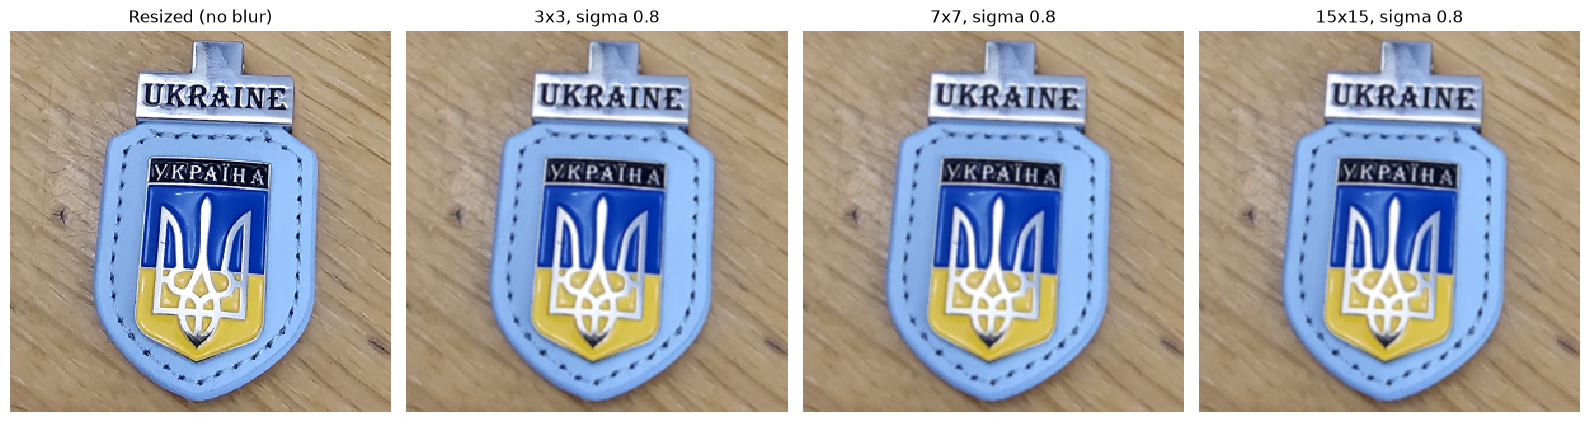

In [10]:
# ---------- Step 6a (optional): fixed sigma, varying kernel ----------
FIXED_SIGMA = 0.8
blurred_fixed = {}
fixed_times = {}

print(f"\n--- Gaussian Blur, fixed sigma = {FIXED_SIGMA} ---")
for k in KERNELS:
    weights = cv2.getGaussianKernel(k[0], FIXED_SIGMA).ravel()   # real weights for this sigma
    cv2.GaussianBlur(resized, k, FIXED_SIGMA)                     # warm-up
    t0 = time.perf_counter()
    for _ in range(N_RUNS):
        out = cv2.GaussianBlur(resized, k, FIXED_SIGMA)
    ms = (time.perf_counter() - t0) / N_RUNS * 1000

    blurred_fixed[k] = out
    fixed_times[k] = ms
    cv2.imwrite(str(RESULTS_DIR / f"task01_blur_{k[0]}x{k[1]}_sigma{FIXED_SIGMA}.png"), out)
    print(f"Kernel {k[0]:>2}x{k[1]:<2} | sigma = {FIXED_SIGMA:.2f} | "
          f"centre weight = {weights[k[0] // 2]:.3f} | time = {ms:.2f} ms | "
          f"PSNR = {cv2.PSNR(resized, out):.2f} dB")

fig, axes = plt.subplots(1, 4, figsize=(16, 5))
panels = [("Resized (no blur)", resized)] + \
         [(f"{k[0]}x{k[1]}, sigma {FIXED_SIGMA}", blurred_fixed[k]) for k in KERNELS]
for ax, (title, img) in zip(axes, panels):
    crop = img[crop_y - size:crop_y + size, crop_x - size:crop_x + size]
    ax.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB), interpolation="nearest")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "task01_step6a_blur_zoom_fixed_sigma.png", dpi=150)
plt.show()

# STEP 7


--- Measurements (reference = resized image) ---
Kernel            sigma  time ms  PSNR dB  sharpness  % sharp
none (resized)        -        -      inf      553.0    100.0
3x3                0.80     3.05    34.39       62.6     11.3
7x7                1.40     3.15    30.33        9.6      1.7
15x15              2.60     2.10    27.91        2.5      0.5


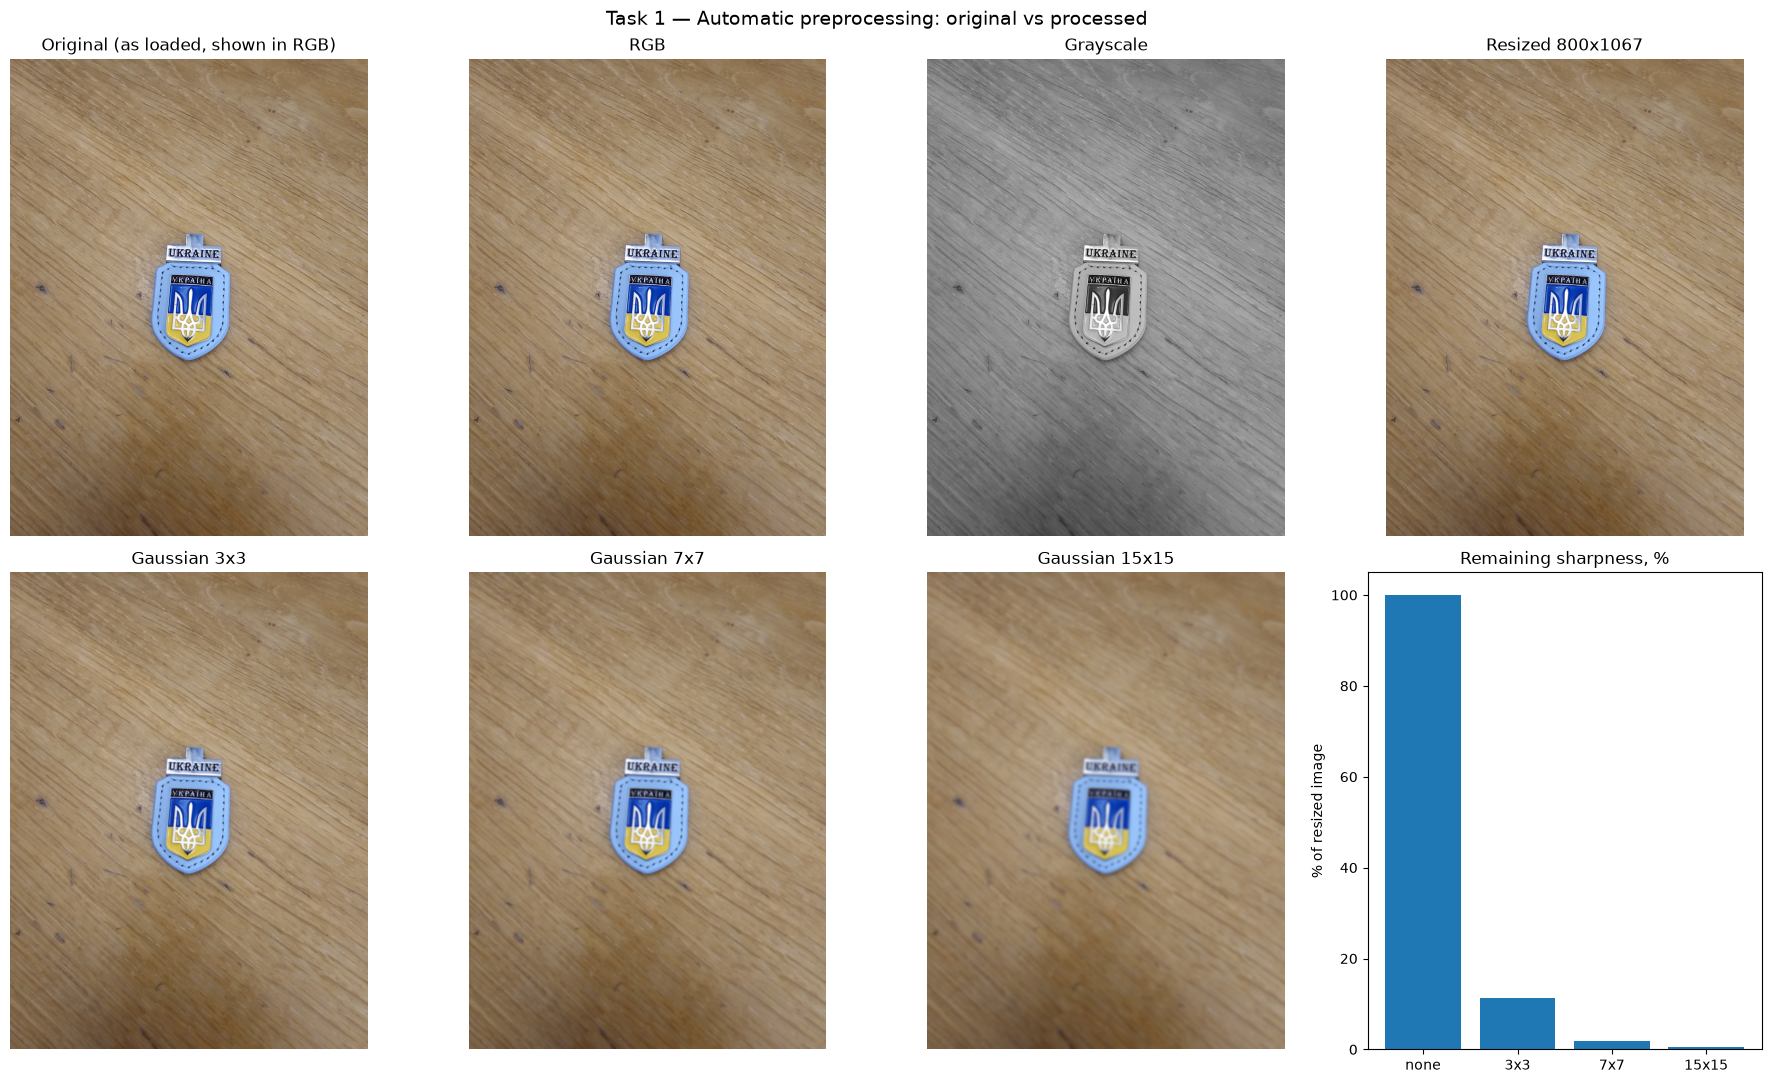

In [11]:
# ---------- Step 7: Comparison figure + measurements ----------
import csv
import numpy as np

def psnr(reference, test):
    """PSNR in dB between two uint8 images of the same size."""
    mse = np.mean((reference.astype(np.float64) - test.astype(np.float64)) ** 2)
    if mse == 0:
        return float("inf")
    return 10 * np.log10(255.0 ** 2 / mse)

def sharpness(bgr):
    """Variance of the Laplacian on the grayscale version (higher = sharper)."""
    g = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    return cv2.Laplacian(g, cv2.CV_64F).var()

# --- measurements table ---
rows = []
base_sharp = sharpness(resized)
rows.append(["none (resized)", "-", "-", "inf", f"{base_sharp:.1f}", "100.0"])
print("\n--- Measurements (reference = resized image) ---")
print(f"{'Kernel':<16}{'sigma':>7}{'time ms':>9}{'PSNR dB':>9}{'sharpness':>11}{'% sharp':>9}")
print(f"{'none (resized)':<16}{'-':>7}{'-':>9}{'inf':>9}{base_sharp:>11.1f}{100.0:>9.1f}")

for k in KERNELS:
    p = psnr(resized, blurred[k])
    s = sharpness(blurred[k])
    sig = 0.3 * ((k[0] - 1) * 0.5 - 1) + 0.8
    pct = 100 * s / base_sharp
    rows.append([f"{k[0]}x{k[1]}", f"{sig:.2f}", f"{blur_times[k]:.2f}",
                 f"{p:.2f}", f"{s:.1f}", f"{pct:.1f}"])
    print(f"{f'{k[0]}x{k[1]}':<16}{sig:>7.2f}{blur_times[k]:>9.2f}{p:>9.2f}{s:>11.1f}{pct:>9.1f}")

with open(RESULTS_DIR / "task01_measurements.csv", "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["kernel", "sigma", "time_ms", "psnr_db", "sharpness", "sharpness_pct"])
    writer.writerows(rows)

# --- full comparison figure (required by the lab) ---
panels = [
    #("Original (BGR as loaded)",       cv2.cvtColor(image, cv2.COLOR_BGR2RGB), None),
    ("Original (as loaded, shown in RGB)", cv2.cvtColor(image, cv2.COLOR_BGR2RGB), None),
    ("RGB",                            image_rgb, None),
    ("Grayscale",                      gray, "gray"),
    (f"Resized {rw}x{rh}",             cv2.cvtColor(resized, cv2.COLOR_BGR2RGB), None),
] + [
    (f"Gaussian {k[0]}x{k[1]}", cv2.cvtColor(blurred[k], cv2.COLOR_BGR2RGB), None)
    for k in KERNELS
]

fig, axes = plt.subplots(2, 4, figsize=(18, 11))
axes = axes.ravel()
for ax, (title, img, cmap) in zip(axes, panels):
    ax.imshow(img, cmap=cmap, vmin=0 if cmap else None, vmax=255 if cmap else None)
    ax.set_title(title)
    ax.axis("off")

# 8th panel: sharpness vs kernel as a bar chart
labels = ["none"] + [f"{k[0]}x{k[1]}" for k in KERNELS]
values = [100.0] + [100 * sharpness(blurred[k]) / base_sharp for k in KERNELS]
axes[7].bar(labels, values)
axes[7].set_title("Remaining sharpness, %")
axes[7].set_ylabel("% of resized image")

plt.suptitle("Task 1 — Automatic preprocessing: original vs processed", fontsize=14)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "task01_comparison.png", dpi=150)
plt.show()